# Spatial Analysis of the 2023 Dutch Election

Share of votes for one party (VVD) in 342 municipalities of the 2023 Dutch general election,
with average income, average house price and population density per municipality.

1. Distributions and log transformation
2. Choropleth map
3. Global spatial autocorrelation (Moran's I) with rook, queen and KNN weights
4. Local Moran's I: hotspots and coldspots
5. Linear regression vs. a spatial lag model (`spreg`)
6. Random forest, bagging and SVR with a province-wise train/test split and grid search
7. Province-wise cross-validation and a map of the prediction errors

All data is merged into the municipality GeoDataFrame first, so every model uses rows in the same
order as the spatial weights.

## 1. Target and features

['GM_NAAM', 'GM_CODE', 'OuderRegioCode', 'GrootOuderRegioCode', 'total_votes', 'VVD', 'Average_House_Price', 'Average_Income', 'Population_Density', 'Population_Increase']

Normally distributed? (Shapiro-Wilk, alpha = 0.05)
Pct_Votes           : No
Average_Income      : No
Average_House_Price : No
Population_Density  : No


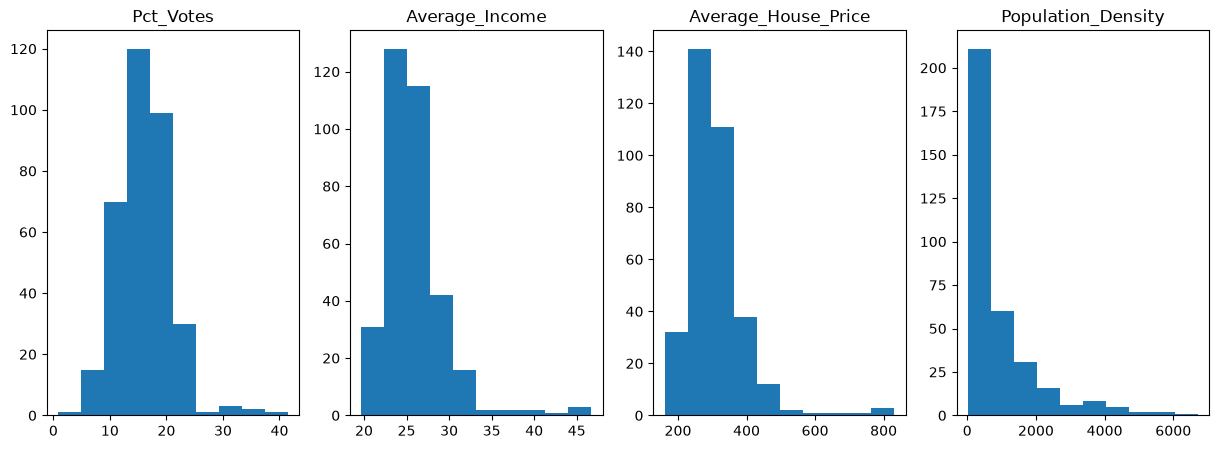

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

df = pd.read_csv("election_2023_municipalities.csv")  # not included in this repository
print(df.columns.to_list())

# Target: share of votes for the party (VVD) in each municipality
df["Pct_Votes"] = df["VVD"] / df["total_votes"] * 100

features = ["Pct_Votes", "Average_Income", "Average_House_Price", "Population_Density"]
plt.figure(figsize=(15, 5))
for i, f in enumerate(features):
    plt.subplot(1, 4, i + 1)
    plt.hist(df[f])
    plt.title(f)

# Shapiro-Wilk test: p < 0.05 rejects normality
print("\nNormally distributed? (Shapiro-Wilk, alpha = 0.05)")
for f in features:
    stat, p = stats.shapiro(df[f])
    print(f"{f:<20}: {'No' if p < 0.05 else 'Yes'}")

In [2]:
# The variables are right-skewed, so they are log-transformed
for f in features:
    df["log_" + f] = np.log(df[f] + 1)

## 2. Choropleth map

Text(0.5, 1.0, 'Choropleth Map of Percentage of Votes')

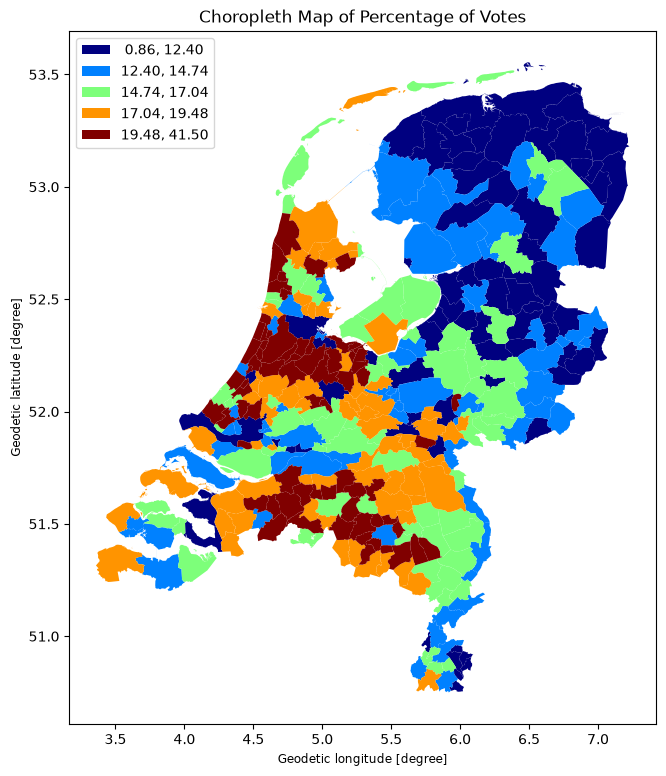

In [3]:
from os.path import join

import geopandas as gpd

# Municipality boundaries 2023 (CBS / Kadaster "Wijk- en buurtkaart")
municipalities = gpd.read_file(join("wijkbuurtkaart_2023_v1", "gemeenten_2023_v1.shp"))

# Keep land polygons only and use longitude/latitude for plotting
land = municipalities.loc[municipalities["H2O"] == "NEE"].to_crs(epsg=4326)

# Bring all election columns into the GeoDataFrame. From here on every analysis uses `land`,
# so the rows always line up with the spatial weights built from it.
land = land.merge(df.drop(columns=["GM_NAAM"]), on="GM_CODE").dropna(subset=["Pct_Votes"]).reset_index(drop=True)

land.plot(figsize=(9, 9), column="Pct_Votes", scheme="QUANTILES", k=5, cmap="jet",
          legend=True, legend_kwds={"loc": "upper left"})
plt.title("Choropleth Map of Percentage of Votes")

## 3. Global spatial autocorrelation

In [4]:
from esda import Moran
from libpysal.weights import KNN, Queen, Rook

spatial_weights = {
    "Rook": Rook.from_dataframe(land, use_index=True),
    "Queen": Queen.from_dataframe(land, use_index=True),
    "KNN (k=3)": KNN.from_dataframe(land, k=3),
    "KNN (k=5)": KNN.from_dataframe(land, k=5),
    "KNN (k=7)": KNN.from_dataframe(land, k=7),
}
for w in spatial_weights.values():
    w.transform = "r"  # row-standardised

log_pct = np.log(land["Pct_Votes"]).values
moran_res = {name: Moran(log_pct, w) for name, w in spatial_weights.items()}

print("\nGlobal Moran's I Results:")
for name, m in moran_res.items():
    print(f"{name:<10}: {m.I:.2f}")

## 4. Local spatial autocorrelation

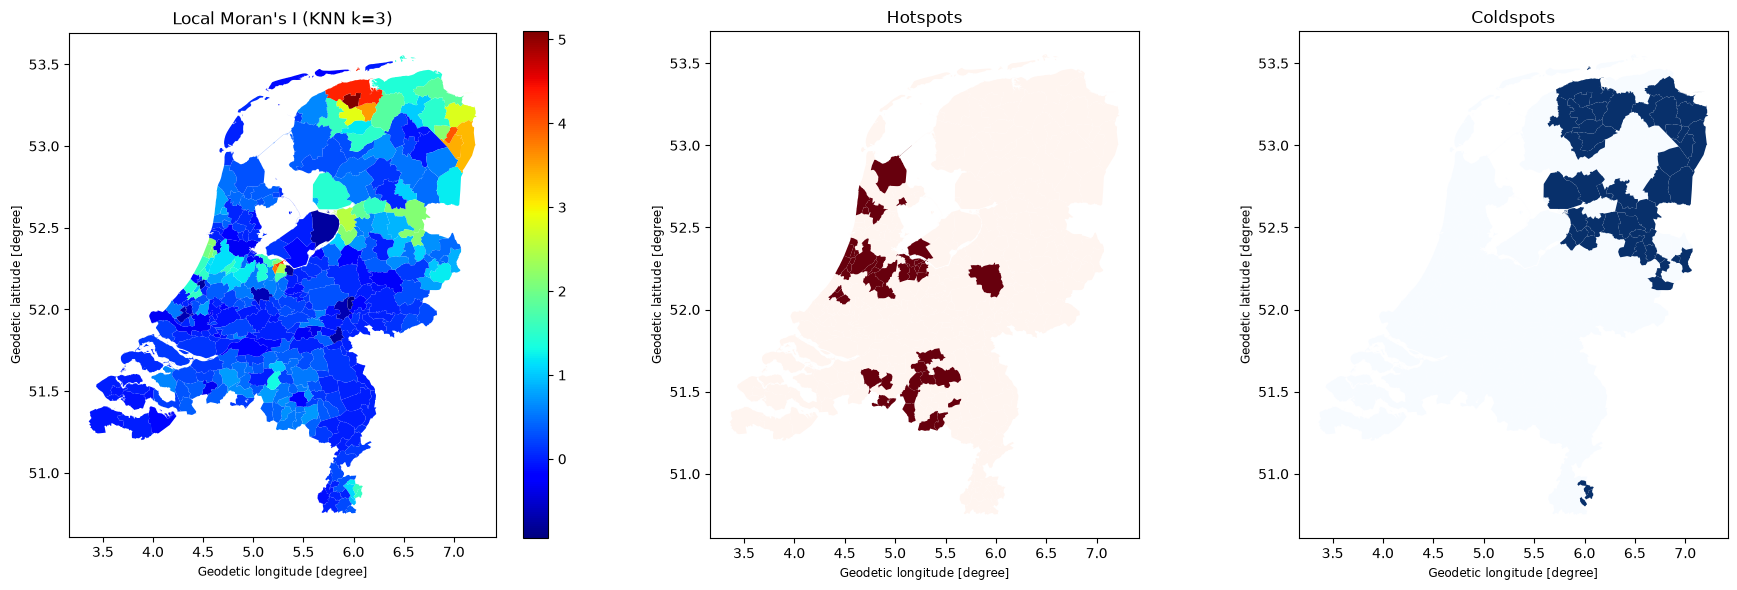

In [5]:
from esda import Moran_Local

# KNN with k = 3 gave the highest global Moran's I
w = spatial_weights["KNN (k=3)"]
lm_knn3 = Moran_Local(log_pct, w)

sig = lm_knn3.p_sim < 0.05
hotspot = sig & (lm_knn3.q == 1)   # high value surrounded by high values
coldspot = sig & (lm_knn3.q == 3)  # low value surrounded by low values

land["local_I"] = lm_knn3.Is
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1); land.plot(column="local_I", cmap="jet", legend=True, ax=plt.gca()); plt.title("Local Moran's I (KNN k=3)")
plt.subplot(1, 3, 2); land.plot(column=hotspot, cmap="Reds", ax=plt.gca()); plt.title("Hotspots")
plt.subplot(1, 3, 3); land.plot(column=coldspot, cmap="Blues", ax=plt.gca()); plt.title("Coldspots")
plt.tight_layout()

## 5. Linear regression vs. spatial lag model

In [6]:
import spreg
from sklearn.metrics import mean_squared_error

variables = ["log_Pct_Votes", "log_Average_Income", "log_Average_House_Price", "log_Population_Density"]
y = land[variables[0]].values
X = land[variables[1:]].values

# Linear regression vs. spatial lag model (GM_Lag), both on all municipalities
ols_model = spreg.OLS(y, X, name_y=variables[0], name_x=variables[1:])
slm_model = spreg.GM_Lag(y, X, w=w, name_y=variables[0], name_x=variables[1:])

mse_ols = mean_squared_error(y, ols_model.predy)
mse_slm = mean_squared_error(y, slm_model.predy)
print(f"MSE OLS: {mse_ols:.5f}")
print(f"MSE SLM: {mse_slm:.5f}")

GM_Lag
MSE OLS: 0.03324
MSE SLM: 0.02930


## 6. Machine learning regressors with a province-wise split

In [7]:
from libpysal.weights import lag_spatial
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit
from sklearn.svm import SVR

# Features: spatial lag of the target, house price and population density (log form)
land["lag_log_Pct_Votes"] = lag_spatial(w, land["log_Pct_Votes"].values)
X = land[["lag_log_Pct_Votes", "log_Average_House_Price", "log_Population_Density"]]
y = land["log_Pct_Votes"]

# Province-wise split: all municipalities of a province are either in train or in test
groups = land["GrootOuderRegioCode"].values
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

regressors = {
    "Random Forest": {"model": RandomForestRegressor(random_state=42),
                      "params": {"n_estimators": [10, 50, 100],
                                 "max_depth": [5, 10, None],
                                 "min_samples_split": [2, 5, 10]}},
    "Bagging": {"model": BaggingRegressor(random_state=42),
                "params": {"n_estimators": [10, 50, 100],
                           "max_samples": [0.2, 0.5, 1.0],
                           "max_features": [0.2, 0.5, 1.0]}},
    "SVR": {"model": SVR(),
            "params": {"C": [0.1, 1, 10],
                       "epsilon": [0.01, 0.1, 0.2],
                       "kernel": ["rbf", "linear", "poly"]}},
}

best_estimators, test_mse = {}, {}
for name, mp in regressors.items():
    print(f"\n{name}")
    grid_search = GridSearchCV(mp["model"], mp["params"], cv=5, scoring="neg_mean_squared_error")
    grid_search.fit(X_train, y_train)
    best_estimators[name] = grid_search.best_estimator_
    test_mse[name] = mean_squared_error(y_test, grid_search.predict(X_test))
    print(f"Best parameters: {grid_search.best_params_}")
    print(f"MSE: {test_mse[name]:.5f}")


Random Forest


Best parameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 10}
MSE: 0.02166

Bagging


Best parameters: {'max_features': 1.0, 'max_samples': 0.5, 'n_estimators': 100}
MSE: 0.02301

SVR


Best parameters: {'C': 1, 'epsilon': 0.1, 'kernel': 'rbf'}
MSE: 0.01957


## 7. Province-wise cross-validation and prediction errors

Model: SVR


Summary statistics of log_Pct_Votes:
count    342.000000
mean       2.798313
std        0.296496
min        0.617976
25%        2.641129
50%        2.833609
75%        2.991708
max        3.749411
Name: log_Pct_Votes, dtype: float64

Summary statistics of Pred_Error:
count    342.000000
mean       0.135807
std        0.153420
min        0.000537
25%        0.053245
50%        0.108042
75%        0.170955
max        2.102857
Name: Pred_Error, dtype: float64


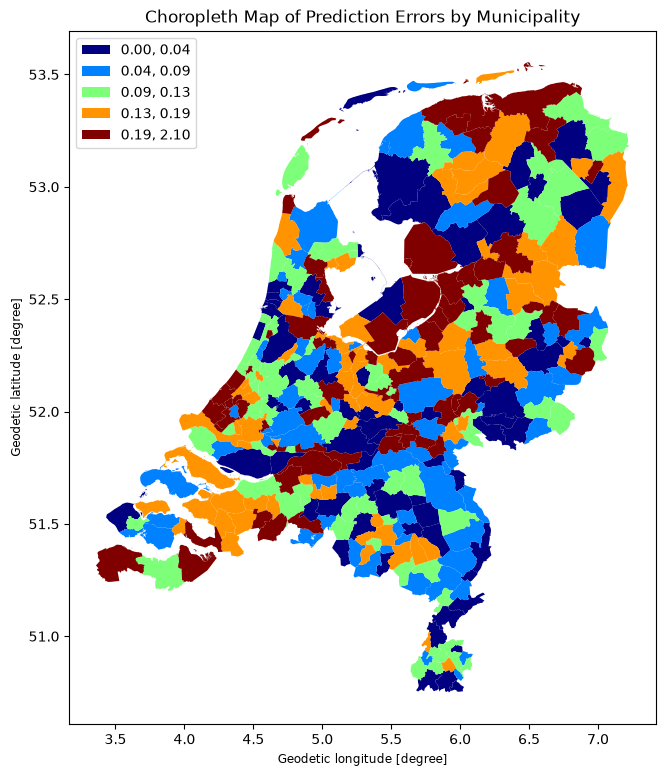

In [8]:
from sklearn.base import clone
from sklearn.model_selection import GroupKFold

# Best model from the comparison above (lowest test MSE), refit in each fold
best_name = min(test_mse, key=test_mse.get)
print(f"Model: {best_name}")
regressor = clone(best_estimators[best_name])

# Group-wise 5-fold cross-validation by province: every municipality is predicted once,
# by a model that never saw its province
errors = np.zeros(len(land))
for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups):
    regressor.fit(X.iloc[train_idx], y.iloc[train_idx])
    errors[test_idx] = np.abs(y.iloc[test_idx] - regressor.predict(X.iloc[test_idx]))

land["Pred_Error"] = errors
land.plot(figsize=(9, 9), column="Pred_Error", scheme="QUANTILES", k=5, cmap="jet",
          legend=True, legend_kwds={"loc": "upper left"})
plt.title("Choropleth Map of Prediction Errors by Municipality")

print("Summary statistics of log_Pct_Votes:")
print(land["log_Pct_Votes"].describe())
print("\nSummary statistics of Pred_Error:")
print(land["Pred_Error"].describe())